RECREATING FIGURE 4 FROM IRM PAPER
Replacing ICP with IRM Games

Running FOU: ones=False, hetero=False, scramble=False

FOU Results:
  ERM       : causal=0.00010±0.00008, non-causal=0.00086±0.00046
  IRMGames  : causal=0.00047±0.00027, non-causal=0.00534±0.00301
  IRM       : causal=0.00011±0.00008, non-causal=0.00041±0.00019

Running FOS: ones=False, hetero=False, scramble=True

FOS Results:
  ERM       : causal=0.00010±0.00006, non-causal=0.00057±0.00032
  IRMGames  : causal=0.00035±0.00018, non-causal=0.00458±0.00262
  IRM       : causal=0.00011±0.00006, non-causal=0.00030±0.00019

Running FEU: ones=False, hetero=True, scramble=False

FEU Results:
  ERM       : causal=0.00915±0.00882, non-causal=1.53361±0.54139
  IRMGames  : causal=0.00541±0.00479, non-causal=0.50343±0.21984
  IRM       : causal=0.01262±0.01215, non-causal=2.21177±0.85060

Running FES: ones=False, hetero=True, scramble=True

FES Results:
  ERM       : causal=0.00747±0.00605, non-causal=1.32397±0.41061
  IRMGames  : 

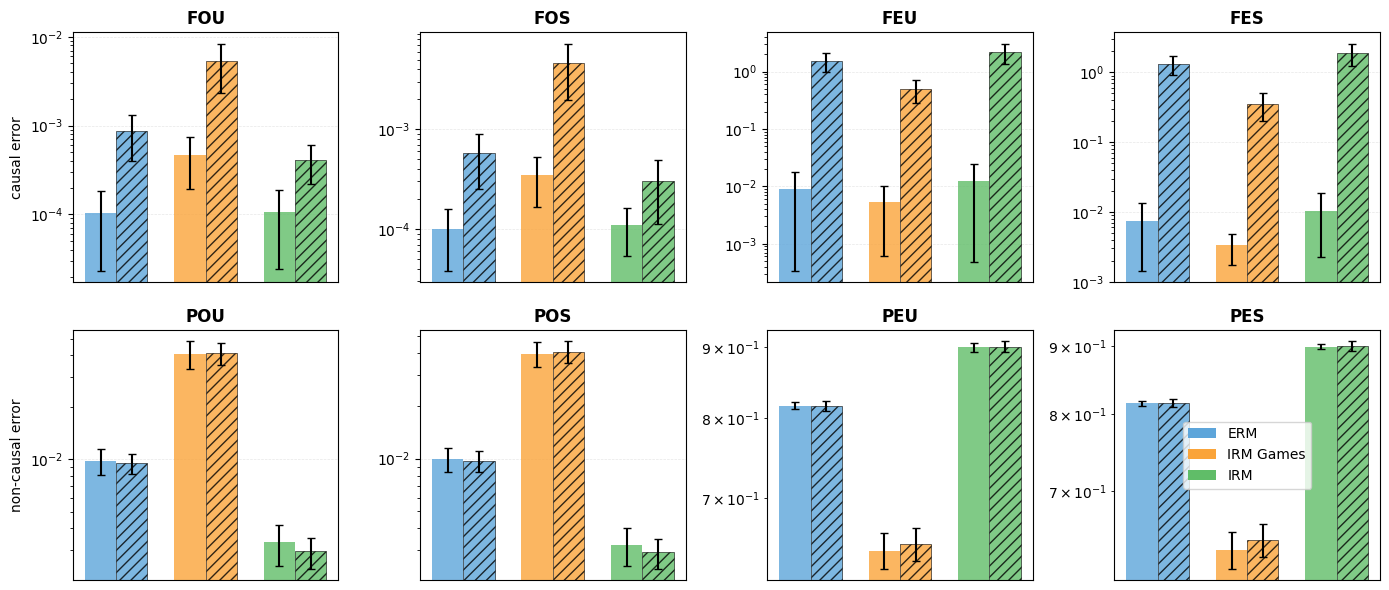


✅ DONE! Plot saved as 'figure4_irm_games.pdf'


In [ ]:
"""
Recreate Figure 4 from IRM Paper
"""

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import matplotlib.patches as mpatches

class ChainEquationModel:
    def __init__(self, dim, ones=True, scramble=False, hetero=True, hidden=False):
        self.hetero = hetero
        self.hidden = hidden
        self.dim = dim // 2
        
        if ones:
            self.wxy = np.eye(self.dim, dtype=np.float32)
            self.wyz = np.eye(self.dim, dtype=np.float32)
        else:
            self.wxy = np.random.randn(self.dim, self.dim).astype(np.float32) / dim
            self.wyz = np.random.randn(self.dim, self.dim).astype(np.float32) / dim
        
        if scramble:
            self.scramble, _ = np.linalg.qr(np.random.randn(dim, dim))
            self.scramble = self.scramble.astype(np.float32)
        else:
            self.scramble = np.eye(dim, dtype=np.float32)
        
        if hidden:
            self.whx = np.random.randn(self.dim, self.dim).astype(np.float32) / dim
            self.why = np.random.randn(self.dim, self.dim).astype(np.float32) / dim
            self.whz = np.random.randn(self.dim, self.dim).astype(np.float32) / dim
        else:
            self.whx = np.eye(self.dim, dtype=np.float32)
            self.why = np.zeros((self.dim, self.dim), dtype=np.float32)
            self.whz = np.zeros((self.dim, self.dim), dtype=np.float32)
    
    def solution(self):
        w = np.concatenate([self.wxy.sum(1), np.zeros(self.dim)]).reshape(-1, 1)
        return w.astype(np.float32), self.scramble
    
    def __call__(self, n, env):
        h = np.random.randn(n, self.dim).astype(np.float32) * env
        x = h @ self.whx + np.random.randn(n, self.dim).astype(np.float32) * env
        
        if self.hetero:
            y = x @ self.wxy + h @ self.why + np.random.randn(n, self.dim).astype(np.float32) * env
            z = y @ self.wyz + h @ self.whz + np.random.randn(n, self.dim).astype(np.float32)
        else:
            y = x @ self.wxy + h @ self.why + np.random.randn(n, self.dim).astype(np.float32)
            z = y @ self.wyz + h @ self.whz + np.random.randn(n, self.dim).astype(np.float32) * env
        
        X = np.concatenate([x, z], axis=1) @ self.scramble
        y_target = y.sum(1, keepdims=True)
        
        return X, y_target


def forward_linear(X, w):
    return X @ w

def mse_loss(predictions, y):
    return np.mean((predictions - y) ** 2)

def mse_gradients(X, predictions, y):
    B = X.shape[0]
    return (2.0 / B) * X.T @ (predictions - y)

def penalty_linear(X, w, y):
    predictions = X @ w
    B = X.shape[0]
    grad = (2.0 / B) * X.T @ (predictions - y)
    return (grad ** 2).sum()

def penalty_gradients_linear(X, w, y):
    B = X.shape[0]
    predictions = X @ w
    residuals = predictions - y
    grad_loss = (2.0 / B) * X.T @ residuals
    H = (2.0 / B) * X.T @ X
    return 2.0 * H @ grad_loss

def errors(w, w_hat):
    w = w.flatten()
    w_hat = w_hat.flatten()
    
    i_causal = np.where(w != 0)[0]
    i_noncausal = np.where(w == 0)[0]
    
    error_causal = np.mean((w[i_causal] - w_hat[i_causal]) ** 2) if len(i_causal) else 0.0
    error_noncausal = np.mean((w[i_noncausal] - w_hat[i_noncausal]) ** 2) if len(i_noncausal) else 0.0
    
    return float(error_causal), float(error_noncausal)


def ensemble_predictions(X, W_list):
    num_models = len(W_list)
    predictions_sum = np.zeros((X.shape[0], 1), dtype=np.float32)
    for w in W_list:
        predictions_sum += X @ w
    return predictions_sum / num_models


def ensemble_gradients(X, y, W_list, env_idx):
    B = X.shape[0]
    num_models = len(W_list)
    ensemble_pred = ensemble_predictions(X, W_list)
    grad = (1.0 / num_models) * (2.0 / B) * X.T @ (ensemble_pred - y)
    return grad


class EmpiricalRiskMinimizer:
    def __init__(self, environments, args):
        self.args = args
        self.w = self._train(environments)
    
    def _train(self, environments):
        X_train = np.vstack([X for X, y in environments])
        y_train = np.vstack([y for X, y in environments])
        
        d = X_train.shape[1]
        w = np.random.randn(d, 1).astype(np.float32) * 0.01
        
        m = np.zeros_like(w)
        v = np.zeros_like(w)
        beta1, beta2, eps = 0.9, 0.999, 1e-8
        lr = self.args['lr']
        
        for step in range(self.args['n_iterations']):
            predictions = forward_linear(X_train, w)
            grad = mse_gradients(X_train, predictions, y_train)
            
            m = beta1 * m + (1 - beta1) * grad
            v = beta2 * v + (1 - beta2) * (grad ** 2)
            
            m_hat = m / (1 - beta1 ** (step + 1))
            v_hat = v / (1 - beta2 ** (step + 1))
            
            w -= lr * m_hat / (np.sqrt(v_hat) + eps)
        
        return w
    
    def solution(self):
        return self.w


class InvariantRiskMinimization:
    def __init__(self, environments, args):
        self.args = args
        self.w = self._train(environments)
    
    def _train(self, environments):
        d = environments[0][0].shape[1]
        w = np.random.randn(d, 1).astype(np.float32) * 0.01
        
        m = np.zeros_like(w)
        v = np.zeros_like(w)
        beta1, beta2, eps = 0.9, 0.999, 1e-8
        lr = self.args['lr']
        
        penalty_weight = 10000.0
        penalty_anneal_iters = self.args['n_iterations'] // 10
        
        for step in range(self.args['n_iterations']):
            total_grad = np.zeros_like(w)
            pw = penalty_weight if step >= penalty_anneal_iters else 1.0
            
            for X, y in environments:
                grad_loss = mse_gradients(X, forward_linear(X, w), y)
                grad_penalty = penalty_gradients_linear(X, w, y)
                total_grad += grad_loss + pw * grad_penalty
            
            total_grad /= len(environments)
            if pw > 1.0:
                total_grad /= pw
            
            m = beta1 * m + (1 - beta1) * total_grad
            v = beta2 * v + (1 - beta2) * (total_grad ** 2)
            
            m_hat = m / (1 - beta1 ** (step + 1))
            v_hat = v / (1 - beta2 ** (step + 1))
            
            w -= lr * m_hat / (np.sqrt(v_hat) + eps)
        
        return w
    
    def solution(self):
        return self.w


class IRMGames:
    def __init__(self, environments, args):
        self.args = args
        self.W_list = self._train(environments)
    
    def _train(self, environments):
        d = environments[0][0].shape[1]
        num_train_envs = len(environments)
        
        W_list = [np.random.randn(d, 1).astype(np.float32) * 0.01 
                  for _ in range(num_train_envs)]
        
        m_list = [np.zeros_like(w) for w in W_list]
        v_list = [np.zeros_like(w) for w in W_list]
        beta1, beta2, eps = 0.9, 0.999, 1e-8
        lr = self.args['lr']
        
        for step in range(self.args['n_iterations']):
            env_idx = step % num_train_envs
            X_env, y_env = environments[env_idx]
            
            grad = ensemble_gradients(X_env, y_env, W_list, env_idx)
            
            m_list[env_idx] = beta1 * m_list[env_idx] + (1 - beta1) * grad
            v_list[env_idx] = beta2 * v_list[env_idx] + (1 - beta2) * (grad ** 2)
            
            m_hat = m_list[env_idx] / (1 - beta1 ** (step + 1))
            v_hat = v_list[env_idx] / (1 - beta2 ** (step + 1))
            
            W_list[env_idx] -= lr * m_hat / (np.sqrt(v_hat) + eps)
        
        return W_list
    
    def solution(self):
        return np.mean(self.W_list, axis=0)

def run_single_configuration(ones, hetero, scramble, n_reps=10, n_iterations=100000):
    """Run experiment for a single configuration"""
    
    np.random.seed(0)  # Fixed seed for reproducibility
    
    all_methods = {
        "ERM": EmpiricalRiskMinimizer,
        "IRMGames": IRMGames,
        "IRM": InvariantRiskMinimization
    }
    
    args = {'lr': 1e-3, 'n_iterations': n_iterations, 'verbose': False, 'alpha': 0.05}
    
    results = {m: {'causal_errors': [], 'noncausal_errors': []} for m in all_methods.keys()}
    
    for rep_i in range(n_reps):
        sem = ChainEquationModel(dim=10, ones=ones, hidden=False, 
                                scramble=scramble, hetero=hetero)
        environments = [sem(1000, e) for e in [0.2, 2.0, 5.0]]
        sem_solution, sem_scramble = sem.solution()
        
        for method_name, method_constructor in all_methods.items():
            method = method_constructor(environments, args)
            method_solution = sem_scramble @ method.solution()
            
            err_causal, err_noncausal = errors(sem_solution, method_solution)
            
            results[method_name]['causal_errors'].append(err_causal)
            results[method_name]['noncausal_errors'].append(err_noncausal)
    
    return results


def get_config_name(ones, hetero, scramble):
    """Convert configuration to name (FOU, PES, etc.)"""
    p_or_f = 'P' if ones else 'F'
    e_or_o = 'E' if hetero else 'O'
    u_or_s = 'S' if scramble else 'U'
    return p_or_f + e_or_o + u_or_s


def plot_paper_figure(all_results, save_path='figure4_reproduction.pdf'):
    """
    Recreate Figure 4 from the IRM paper
    
    all_results: dict mapping config_name -> results dict
    """
    
    # Configuration order for the plot (same as paper)
    configs_row1 = ['FOU', 'FOS', 'FEU', 'FES']
    configs_row2 = ['POU', 'POS', 'PEU', 'PES']
    all_configs = configs_row1 + configs_row2
    
    # Method order and colors (ERM, ICP/Games, IRM)
    methods = ['ERM', 'IRMGames', 'IRM']
    colors = ['#5DA5DA', '#FAA43A', '#60BD68']  # Blue, Orange, Green
    
    fig, axes = plt.subplots(2, 4, figsize=(14, 6))
    axes = axes.flatten()
    
    for idx, config_name in enumerate(all_configs):
        ax = axes[idx]
        
        if config_name not in all_results:
            print(f"Warning: {config_name} not found in results")
            continue
        
        results = all_results[config_name]
        
        # Prepare data
        causal_means = []
        causal_stds = []
        noncausal_means = []
        noncausal_stds = []
        
        for method in methods:
            causal_means.append(np.mean(results[method]['causal_errors']))
            causal_stds.append(np.std(results[method]['causal_errors']))
            noncausal_means.append(np.mean(results[method]['noncausal_errors']))
            noncausal_stds.append(np.std(results[method]['noncausal_errors']))
        
        # Plot settings
        n_methods = len(methods)
        x = np.arange(n_methods)
        width = 0.35
        
        # Plot causal errors (solid bars)
        bars1 = ax.bar(x - width/2, causal_means, width, yerr=causal_stds,
                       color=colors, alpha=0.8, capsize=3, label='causal')
        
        # Plot non-causal errors (hatched bars)
        bars2 = ax.bar(x + width/2, noncausal_means, width, yerr=noncausal_stds,
                       color=colors, alpha=0.8, capsize=3, hatch='///', 
                       edgecolor='black', linewidth=0.5, label='non-causal')
        
        # Formatting
        ax.set_yscale('log')
        ax.set_xticks([])
        ax.set_title(config_name, fontsize=12, fontweight='bold')
        
        # Y-axis labels only on left column
        if idx % 4 == 0:
            if idx < 4:
                ax.set_ylabel('causal error', fontsize=10)
            else:
                ax.set_ylabel('non-causal error', fontsize=10)
        
        # Grid
        ax.grid(axis='y', alpha=0.3, linestyle='--', linewidth=0.5)
        ax.set_axisbelow(True)
    
    # Create legend
    legend_elements = [
        mpatches.Patch(facecolor='#5DA5DA', label='ERM'),
        mpatches.Patch(facecolor='#FAA43A', label='IRM Games'),
        mpatches.Patch(facecolor='#60BD68', label='IRM')
    ]
    
    # Add legend to last subplot
    axes[-1].legend(handles=legend_elements, loc='center', frameon=True)
    
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"\nPlot saved to: {save_path}")
    plt.show()

print("="*70)
print("RECREATING FIGURE 4 FROM IRM PAPER")
print("Replacing ICP with IRM Games")
print("="*70)

configurations = [
    # (ones, hetero, scramble)
    (False, False, False),  # FOU
    (False, False, True),   # FOS
    (False, True, False),   # FEU
    (False, True, True),    # FES
    (True, False, False),   # POU
    (True, False, True),    # POS
    (True, True, False),    # PEU
    (True, True, True),     # PES
]

all_results = {}

for ones, hetero, scramble in configurations:
    config_name = get_config_name(ones, hetero, scramble)
    print(f"\n{'='*70}")
    print(f"Running {config_name}: ones={ones}, hetero={hetero}, scramble={scramble}")
    print(f"{'='*70}")
    
    results = run_single_configuration(
        ones=ones,
        hetero=hetero,
        scramble=scramble,
        n_reps=10,
        n_iterations=100000  # Same as paper
    )
    
    all_results[config_name] = results
    
    # Print summary for this configuration
    print(f"\n{config_name} Results:")
    for method in ['ERM', 'IRMGames', 'IRM']:
        c_mean = np.mean(results[method]['causal_errors'])
        c_std = np.std(results[method]['causal_errors'])
        nc_mean = np.mean(results[method]['noncausal_errors'])
        nc_std = np.std(results[method]['noncausal_errors'])
        print(f"  {method:10s}: causal={c_mean:.5f}±{c_std:.5f}, "
              f"non-causal={nc_mean:.5f}±{nc_std:.5f}")

print("\n" + "="*70)
print("ALL CONFIGURATIONS COMPLETE - GENERATING PLOT")
print("="*70)

# Generate the plot
plot_paper_figure(all_results, save_path='figure4_irm_games.pdf')

print("\n✅ DONE! Plot saved as 'figure4_irm_games.pdf'")


✅ Subset plot saved as 'figure4_subset.pdf'


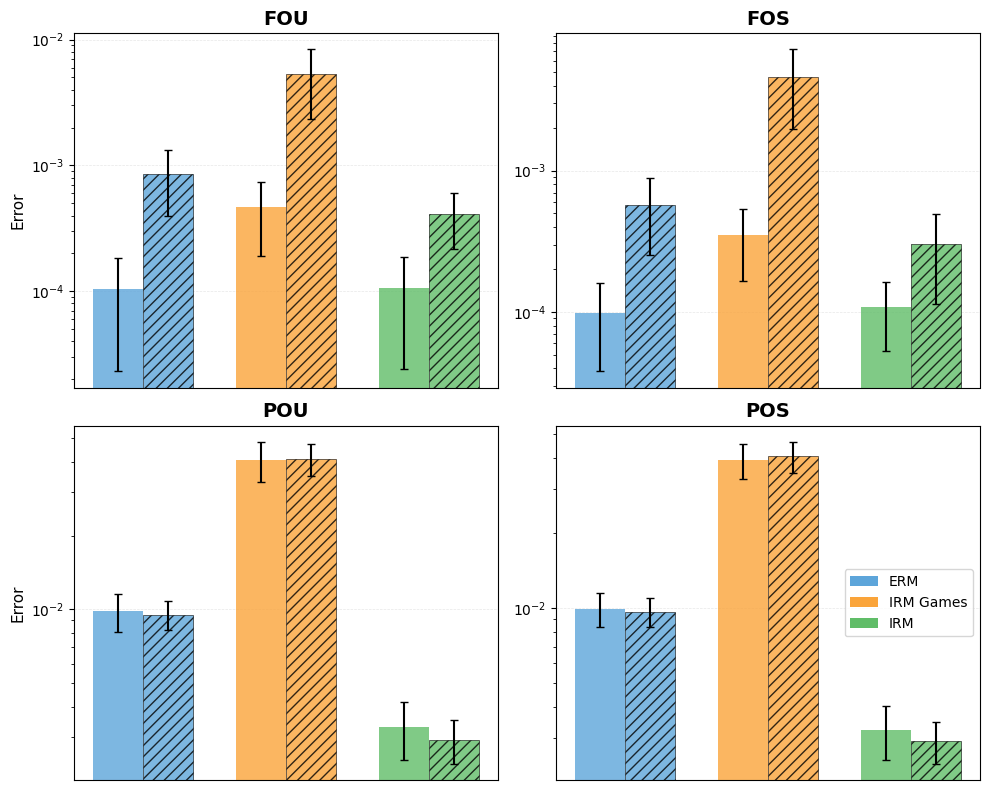


SUMMARY TABLE (FOU, FOS, POU, POS)

FOU:
  ERM       : causal=0.00010  non-causal=0.00086
  IRMGames  : causal=0.00047  non-causal=0.00534
  IRM       : causal=0.00011  non-causal=0.00041

FOS:
  ERM       : causal=0.00010  non-causal=0.00057
  IRMGames  : causal=0.00035  non-causal=0.00458
  IRM       : causal=0.00011  non-causal=0.00030

POU:
  ERM       : causal=0.00982  non-causal=0.00951
  IRMGames  : causal=0.04074  non-causal=0.04117
  IRM       : causal=0.00331  non-causal=0.00294

POS:
  ERM       : causal=0.00994  non-causal=0.00967
  IRMGames  : causal=0.03945  non-causal=0.04064
  IRM       : causal=0.00324  non-causal=0.00292


In [ ]:
"""
Plots only FOU, FOS, POU, POS (4 configurations instead of 8)
"""

configs_to_plot = ['FOU', 'FOS', 'POU', 'POS']
methods = ['ERM', 'IRMGames', 'IRM']
colors = ['#5DA5DA', '#FAA43A', '#60BD68']

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()

for idx, config_name in enumerate(configs_to_plot):
    ax = axes[idx]
    
    if config_name not in all_results:
        print(f"Warning: {config_name} not in results")
        continue
    
    results = all_results[config_name]
    
    # Get means and stds
    causal_means = [np.mean(results[m]['causal_errors']) for m in methods]
    causal_stds = [np.std(results[m]['causal_errors']) for m in methods]
    noncausal_means = [np.mean(results[m]['noncausal_errors']) for m in methods]
    noncausal_stds = [np.std(results[m]['noncausal_errors']) for m in methods]
    
    # Plot
    x = np.arange(len(methods))
    width = 0.35
    
    # Solid bars for causal
    ax.bar(x - width/2, causal_means, width, yerr=causal_stds,
           color=colors, alpha=0.8, capsize=3)
    
    # Hatched bars for non-causal
    ax.bar(x + width/2, noncausal_means, width, yerr=noncausal_stds,
           color=colors, alpha=0.8, capsize=3, hatch='///', 
           edgecolor='black', linewidth=0.5)
    
    # Formatting
    ax.set_yscale('log')
    ax.set_xticks([])
    ax.set_title(config_name, fontsize=14, fontweight='bold')
    ax.grid(axis='y', alpha=0.3, linestyle='--', linewidth=0.5)
    ax.set_axisbelow(True)
    
    # Y-labels on left column
    if idx % 2 == 0:
        ax.set_ylabel('Error', fontsize=11)

# Add legend
legend_elements = [
    mpatches.Patch(facecolor='#5DA5DA', label='ERM'),
    mpatches.Patch(facecolor='#FAA43A', label='IRM Games'),
    mpatches.Patch(facecolor='#60BD68', label='IRM')
]
axes[-1].legend(handles=legend_elements, loc='center right', 
                frameon=True, fontsize=10)

plt.tight_layout()
plt.savefig('figure4_subset.pdf', dpi=300, bbox_inches='tight')
print("\n✅ Subset plot saved as 'figure4_subset.pdf'")
plt.show()

# Print summary table
print("\n" + "="*60)
print("SUMMARY TABLE (FOU, FOS, POU, POS)")
print("="*60)
for config_name in configs_to_plot:
    print(f"\n{config_name}:")
    results = all_results[config_name]
    for method in methods:
        c_mean = np.mean(results[method]['causal_errors'])
        nc_mean = np.mean(results[method]['noncausal_errors'])
        print(f"  {method:10s}: causal={c_mean:.5f}  non-causal={nc_mean:.5f}")